# RQ3: how neighbor information enters the predictor (unified supervised-200 results)

Replaces the old RQ3 analysis (typed HGT, untyped HGT-U, two training schedules, ten splits, three N2V seeds).
Reads the supervisor's package `hetmap-supervised200-results-20261015` and does **not** train anything.

**New RQ3 design (file graph, merged dependency relation, 200 supervised epochs, no self-training):**

| Factor | Levels |
|---|---|
| Input vector | W2V, N2V, UXC$_{ZS}$, UXC$_{FT}$ (all four are back in RQ3) |
| Predictor | HGT, GAT, neighbor-MLP |
| Neighbor condition | `off`; `directed` (dependencies in their original direction); `undirected` (bidirectional) |
| Repetition | 100 paired splits per system, ten systems (one frozen embedding per system) |

Effects are **paired within-split differences** (same system, split, initial labeled set and initial weights). Each system's effect is the median over its
100 splits; a table cell is the median of these ten system effects, followed by the number of systems with a positive median and the numbers of
Holm-significant gains / losses (paired Wilcoxon, one Holm family per representation, model, contrast and metric = ten tests).
This is *not* the difference of two medians; the package exports both and they can have different signs, so never mix them.
For MLP, off is `[x, 0]` and on is `[x, mean(incoming neighbors)]`; GAT uses no self-loops.

| Section | What it does | Writes |
|---|---|---|
| 1-3 | Config, load, helpers | |
| 4 | On/off and direction statistics (and encoder contrasts) | CSVs in `results/unified200/stats/` |
| 5 | Summary table by input vector | `rq3_systems_body.tex` (`tab:rq3_reps`) |
| 6 | Per-system tables | `rq3_n2v.tex` (`tab:rq3_systems`), `rq3_systems_{rep}.tex` |
| 7 | Figures | `rq3_n2v.pdf`, `rq3_onoff_*.pdf`, `rq3_effects_heatmap_*.pdf` |
| 8 | Which predictor is best on each graph | `rq3_encoders.tex` |
| 9 | Numbers quoted in the text, checks against the package | |

**Dropped because the new run has no matching experiment:** rewired / shuffled N2V controls, the GAT and embedding-seed controls,
the self-training vs supervised comparison, and the HGT-U model (typed edges no longer exist; directed-vs-undirected replaces that contrast).

## 1. Config, paths and loader

In [1]:
import json, warnings
from itertools import combinations
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon

warnings.filterwarnings("ignore")
plt.rcParams["text.usetex"] = True
try:  # fall back to mathtext if no LaTeX installation is available
    _f = plt.figure(); _f.text(0.5, 0.5, r"$\langle k \rangle$"); _f.canvas.draw(); plt.close(_f)
except Exception as _e:
    print("LaTeX unavailable, using mathtext:", type(_e).__name__)
    plt.rcParams["text.usetex"] = False
sns.set_theme(
    style="ticks",
    rc={
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.spines.left": True, "axes.spines.bottom": True,
        "axes.edgecolor": "black", "axes.linewidth": 1,
        "xtick.bottom": True, "ytick.left": True,
        "xtick.major.size": 3, "ytick.major.size": 3,
        "xtick.major.width": 1, "ytick.major.width": 1,
        "axes.grid": True, "axes.grid.axis": "x",
        "grid.alpha": 0.7, "grid.linestyle": "-", "grid.linewidth": 0.7,
    },
)
plt.rcParams.update({
    "font.size": 11, "axes.axisbelow": True,
    "grid.alpha": 0.4, "grid.linestyle": "-", "grid.linewidth": 0.5,
})
ALPHA = 0.05

LaTeX unavailable, using mathtext: RuntimeError


<Figure size 640x480 with 0 Axes>

In [2]:
# ── Paths ───────────────────────────────────────────────────────────────────────
# The notebook finds the paper folder (the one holding 3a_results.tex) and reads the supervisor's
# package either from an extracted folder or straight from the ZIP in the repo root.
def _find_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "3a_results.tex").exists():
            return q
    raise FileNotFoundError("Run this notebook from inside the HetMap paper folder (the one with 3a_results.tex).")

ROOT = _find_root()
PKG_NAME = "hetmap-supervised200-results-20261015"
RUN_DIR = "scenario1-run/unified-supervised200-20261015/outputs/analysis"   # long-format.csv, rq*-per-run.csv, ...
AUDIT_DIR = "repro-audit/unified200-20261015"                              # supervisor's statistics / directory audit


class Package:
    """Read-only access to the supervisor's results package (extracted folder or .zip)."""
    def __init__(self, root):
        bases = [root, root / "results", root.parent]
        self.folder = next((b / PKG_NAME for b in bases if (b / PKG_NAME).is_dir()), None)
        self.zip = None
        if self.folder is None:
            z = next((b / f"{PKG_NAME}.zip" for b in bases if (b / f"{PKG_NAME}.zip").exists()), None)
            if z is None:
                raise FileNotFoundError(f"Put {PKG_NAME}.zip (or the extracted folder) next to this notebook.")
            self.zip = zipfile.ZipFile(z)
        self.source = self.folder or Path(self.zip.filename)

    def open(self, rel):
        return (self.folder / rel).open("rb") if self.folder else self.zip.open(f"{PKG_NAME}/{rel}")

    def csv(self, rel, **kw):
        with self.open(rel) as fh:
            return pd.read_csv(fh, **kw)

    def json(self, rel):
        with self.open(rel) as fh:
            return json.load(fh)


PKG = Package(ROOT)

# Where outputs go. WRITE_TO_PAPER=True overwrites generated/*.tex and Images/*.pdf (git keeps the old versions);
# False writes everything under results/unified200/preview/ so the paper folder is untouched.
WRITE_TO_PAPER = True
OUT = ROOT / "results" / "unified200"
STATS_DIR = OUT / "stats"
TEX_DIR = ROOT / "generated" if WRITE_TO_PAPER else OUT / "preview" / "generated"
FIG_DIR = ROOT / "Images" if WRITE_TO_PAPER else OUT / "preview" / "Images"
for _d in (STATS_DIR, TEX_DIR, FIG_DIR):
    _d.mkdir(parents=True, exist_ok=True)


def save_stats(df, name):
    p = STATS_DIR / name
    df.to_csv(p, index=False)
    print(f"saved {p.relative_to(ROOT)}  ({len(df)} rows)")


def save_tex(text, name):
    p = TEX_DIR / name
    p.write_text(text)
    print(f"wrote {p.relative_to(ROOT)}")


def fig_path(name):
    return FIG_DIR / name


print("ROOT    :", ROOT)
print("PACKAGE :", PKG.source)
print("TEX     :", TEX_DIR.relative_to(ROOT))
print("FIGURES :", FIG_DIR.relative_to(ROOT))

SYSTEMS_RAW = ["A.UML", "C.Img", "Jabref", "Lucene", "SH-3D", "TeamMates", "Bash", "HDF", "Chrome", "HDC"]
SYS_RENAME = {"Jabref": "JabRef", "TeamMates": "T.Mates"}
DATASET_ORDER = [SYS_RENAME.get(s, s) for s in SYSTEMS_RAW]
METRICS = ["f1_macro", "f1_micro"]
METRIC_NAME = {"f1_macro": "Macro-F1", "f1_micro": "Micro-F1"}
REP_LABEL = {"W2V": "W2V", "N2V": "N2V", "UXC_ZS": r"\zs{}", "UXC_FT": r"\ft{}"}        # LaTeX macros of the paper
REP_PLOT = {"W2V": "W2V", "N2V": "N2V", "UXC_ZS": r"UXC$_{ZS}$", "UXC_FT": r"UXC$_{FT}$"}   # matplotlib labels
REP_COLOR = {"W2V": "#A6CEE3", "N2V": "#B2DF8A", "UXC_ZS": "#FB9A99", "UXC_FT": "#CAB2D6"}

ROOT    : /home/user/HetMap
PACKAGE : /home/user/HetMap/hetmap-supervised200-results-20261015.zip
TEX     : generated
FIGURES : Images


## 2. Load and validate

In [3]:
long = PKG.csv(f"{RUN_DIR}/long-format.csv")
assert len(long) == 45000 and PKG.json(f"{RUN_DIR}/validation.json")["complete"] is True

# RQ3 = every F-configuration fit: 4 representations x 3 models x 3 conditions x 10 systems x 100 splits
rq3 = long[long.config == "F"].copy()
assert len(rq3) == 36000
n = rq3.groupby(["system", "representation", "model", "condition"]).size()
assert (n == 100).all() and len(n) == 360, n.describe()

ref = PKG.csv(f"{RUN_DIR}/rq3-per-run.csv")
k = ["system", "representation", "config", "model", "condition", "run_id"]
m = ref.merge(rq3, on=k, suffixes=("_ref", ""), validate="one_to_one")
assert len(m) == 36000 and np.allclose(m.f1_macro, m.f1_macro_ref) and np.allclose(m.f1_micro, m.f1_micro_ref)
print("OK: 36,000 RQ3 rows match rq3-per-run.csv | models:", sorted(rq3.model.unique()), "| conditions:", sorted(rq3.condition.unique()))

REPS = ["N2V", "W2V", "UXC_ZS", "UXC_FT"]                  # column order of the old table
MODELS = ["HGT", "GAT", "NeighborMLP"]
MODEL_TEX = {"HGT": "HGT", "GAT": "GAT", "NeighborMLP": r"\mlp{}"}
MODEL_PLOT = {"HGT": "HGT", "GAT": "GAT", "NeighborMLP": r"$\mathcal{N}_\mathrm{MLP}$"}
CONTRASTS = [("directed", "off"), ("undirected", "off"), ("undirected", "directed")]
CONTRAST_TEX = {"directed-off": "dir.$-$off", "undirected-off": "undir.$-$off", "undirected-directed": "undir.$-$dir."}

OK: 36,000 RQ3 rows match rq3-per-run.csv | models: ['GAT', 'HGT', 'NeighborMLP'] | conditions: ['directed', 'off', 'undirected']


## 3. Statistical helpers

In [4]:
# ── Statistical helpers (same procedure as the supervisor's analyze_results.py) ─────────────────
# Paired two-sided Wilcoxon signed-rank on the 100 split-level differences (normal approximation, differences
# rounded to 12 decimals), Cliff's delta, Holm correction within each comparison family and metric.
def cliff_band(d):
    a = abs(d)
    return "N" if a < 0.147 else "S" if a < 0.33 else "M" if a < 0.474 else "L"


def holm(p):
    """Holm-adjusted p-values in the original order."""
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    prev = 0.0
    for rank, idx in enumerate(order):
        prev = min(max((len(p) - rank) * p[idx], prev), 1.0)
        adj[idx] = prev
    return adj


def _cell(df, system):
    g = df[df["system"] == system].set_index("run_id").sort_index()
    assert list(g.index) == list(range(100)), f"{system}: expected run_id 0..99"
    return g


def paired_compare(a, b, scope, family, **labels):
    """Compare two long-format slices (a minus b), per system and metric. Rows are paired by run_id and
    must share the same initial labeled set (labeled_ids_sha256)."""
    rows = []
    for system in SYSTEMS_RAW:
        ga, gb = _cell(a, system), _cell(b, system)
        assert (ga.labeled_ids_sha256 == gb.labeled_ids_sha256).all(), f"{system}: unpaired splits in {family}"
        for metric in METRICS:
            x, y = ga[metric].to_numpy(), gb[metric].to_numpy()
            diff = np.round(x - y, 12)
            p = wilcoxon(diff, alternative="two-sided", method="approx").pvalue if np.any(diff) else 1.0
            delta = float(np.sign(x[:, None] - y[None, :]).mean())
            rows.append(dict(
                scope=scope, family=family, system=system, metric=metric,
                median_a=np.median(x), median_b=np.median(y), difference_of_medians=np.median(x) - np.median(y),
                median_paired_delta=np.median(diff), mean_paired_delta=diff.mean(),
                q25_paired_delta=np.percentile(diff, 25), q75_paired_delta=np.percentile(diff, 75),
                positive_splits=int((diff > 0).sum()), negative_splits=int((diff < 0).sum()), p=p,
                cliffs_delta=delta, cliffs_band=cliff_band(delta), **labels))
    return rows


def finish_stats(rows):
    """Holm within (scope, family, metric); a family is whatever the caller put in `family`."""
    S = pd.DataFrame(rows)
    S["p_holm"] = np.nan
    for _, g in S.groupby(["scope", "family", "metric"]):
        S.loc[g.index, "p_holm"] = holm(g["p"].to_numpy())
    S["significant"] = S["p_holm"] < ALPHA
    S["system"] = S["system"].replace(SYS_RENAME)
    return S


def summarize(S, keys):
    """One row per comparison: median over systems, number of positive systems, significant up / down."""
    out = []
    for key, g in S.groupby(keys, dropna=False):
        out.append(dict(zip(keys, key), **{
            "median_system_difference": g.difference_of_medians.median(),
            "median_system_paired_delta": g.median_paired_delta.median(),
            "positive_systems": int((g.difference_of_medians > 1e-10).sum()),
            "paired_positive_systems": int((g.median_paired_delta > 1e-10).sum()),
            "significant_positive": int((g.significant & (g.median_paired_delta > 0)).sum()),
            "significant_negative": int((g.significant & (g.median_paired_delta < 0)).sum()),
            "large_positive": int((g.significant & (g.cliffs_delta >= .474)).sum()),
            "min_positive_splits": int(g.positive_splits.min()),
        }))
    return pd.DataFrame(out)


def check_against_package(S, scope, extra=()):
    """Recomputed statistics must equal the supervisor's paired_statistics.csv (p, Holm-p, medians, Cliff's delta)."""
    ref = PKG.csv(f"{AUDIT_DIR}/paired_statistics.csv")
    ref = ref[ref.scope == scope].copy()
    ref["system"] = ref["system"].replace(SYS_RENAME)
    key = ["family", "system", "metric", *extra]
    m = S[S.scope == scope].merge(ref, on=key, suffixes=("", "_ref"), validate="one_to_one")
    assert len(m) == len(ref) == (S.scope == scope).sum(), f"{scope}: row mismatch"
    for c in ["median_a", "median_b", "median_paired_delta", "p", "p_holm", "cliffs_delta"]:
        assert np.allclose(m[c], m[c + "_ref"], rtol=1e-9, atol=1e-12), f"{scope}: {c} differs from the package"
    assert (m.significant == m.significant_ref).all()
    print(f"OK: {scope} statistics ({len(m)} tests) reproduce paired_statistics.csv")


# ── LaTeX helpers (shading rules inferred from the existing tables: <1: 25, 1-3: 45, 3-6: 70, >=6: 100) ─
def shade(x):
    a = abs(x)
    return 25 if a < 1 else 45 if a < 3 else 70 if a < 6 else 100


def tex_signed(x, nd=1):
    r = round(float(x), nd)
    if r == 0:
        return f"{0:.{nd}f}"
    return f"+{r:.{nd}f}" if r > 0 else f"$-${abs(r):.{nd}f}"


def shaded(x, text):
    return f"\\{'g' if x >= 0 else 'r'}c{{{shade(x)}}}{text}"

---
## 4. Statistics

* `RQ3` scope: for each representation and model, `directed-off`, `undirected-off` and `undirected-directed` (ten systems per Holm family).
* `encoders` scope: GAT vs HGT, neighbor-MLP vs HGT and GAT vs neighbor-MLP on each fixed graph condition (off / directed / undirected).

In [5]:
rows = []
for rep in REPS:
    for model in MODELS:
        r = rq3[(rq3.representation == rep) & (rq3.model == model)]
        for a, b in CONTRASTS:
            rows += paired_compare(r[r.condition == a], r[r.condition == b], "RQ3", f"{rep}/{model}/{a}-{b}",
                                   contrast=f"{a}-{b}", representation=rep, model=model)
rq3_stats = finish_stats(rows)
check_against_package(rq3_stats, "RQ3")

rows = []
for rep in REPS:
    for cond in ["off", "directed", "undirected"]:
        r = rq3[(rq3.representation == rep) & (rq3.condition == cond)]
        for a, b in [("GAT", "HGT"), ("NeighborMLP", "HGT"), ("GAT", "NeighborMLP")]:
            rows += paired_compare(r[r.model == a], r[r.model == b], "encoders", f"{rep}/{cond}/{a}-{b}",
                                   contrast=f"{a}-{b}", representation=rep, condition=cond)
enc_stats = finish_stats(rows)
check_against_package(enc_stats, "encoders")

save_stats(rq3_stats, "rq3_paired_statistics.csv")
save_stats(enc_stats, "rq3_encoder_paired_statistics.csv")
rq3_summary = summarize(rq3_stats, ["scope", "representation", "model", "contrast", "metric"])
enc_summary = summarize(enc_stats, ["scope", "representation", "condition", "contrast", "metric"])
save_stats(rq3_summary, "rq3_summary.csv")
save_stats(enc_summary, "rq3_encoder_summary.csv")

display(rq3_summary[rq3_summary.metric == "f1_macro"]
        .pivot_table(index=["model", "contrast"], columns="representation", values="median_system_paired_delta")
        [REPS].round(2))

OK: RQ3 statistics (720 tests) reproduce paired_statistics.csv


OK: encoders statistics (720 tests) reproduce paired_statistics.csv
saved results/unified200/stats/rq3_paired_statistics.csv  (720 rows)
saved results/unified200/stats/rq3_encoder_paired_statistics.csv  (720 rows)


saved results/unified200/stats/rq3_summary.csv  (72 rows)
saved results/unified200/stats/rq3_encoder_summary.csv  (72 rows)


representation                    N2V   W2V  UXC_ZS  UXC_FT
model       contrast                                       
GAT         directed-off        -2.84  1.46    3.79    0.67
            undirected-directed  3.81  1.92    3.33    2.98
            undirected-off       1.42  5.56    8.17    3.77
HGT         directed-off        -0.64  0.23    1.64    0.72
            undirected-directed  0.34  0.72   -0.03    0.57
            undirected-off       0.49  2.94    1.79    0.91
NeighborMLP directed-off        -0.65  3.41    4.81    2.85
            undirected-directed  1.62  1.33    3.54    3.11
            undirected-off       1.19  5.08    7.71    5.77

## 5. Table `tab:rq3_reps` (`rq3_systems_body.tex`)

Median over ten systems of the paired change (F1 points); in parentheses the number of systems with a positive paired median and the
significant gains / losses. The third contrast, undirected minus directed, isolates the effect of making dependencies bidirectional.

In [6]:
def summ_row(rep, model, contrast, metric):
    r = rq3_summary[(rq3_summary.representation == rep) & (rq3_summary.model == model)
                    & (rq3_summary.contrast == contrast) & (rq3_summary.metric == metric)]
    assert len(r) == 1
    return r.iloc[0]

def tex_rq3_reps():
    L = [r"\begin{table*}[t]", r"\centering",
         r"\caption{Change in F1 when neighbor information is switched on, by input vector and graph condition. Each cell gives the median over ten systems of "
         r"the paired within-split change in F1 points, followed in parentheses by the number of systems with a positive median change and the numbers of "
         r"significant positive and negative changes (paired Wilcoxon, Holm). Dir.: dependencies in their original direction; undir.: bidirectional; "
         r"off: no neighbor information. Shading marks the median change: blue for gains, purple for losses, and darker for larger changes.\label{tab:rq3_reps}}",
         "", r"\begin{adjustbox}{max width=\textwidth}", r"\renewcommand{\arraystretch}{1.1}", r"\begin{tabular}{llrrrrrrrr}", r"\toprule",
         r"& & \multicolumn{2}{c}{N2V} & \multicolumn{2}{c}{W2V} & \multicolumn{2}{c}{\zs{}} & \multicolumn{2}{c}{\ft{}} \\",
         r"\cmidrule(lr){3-4}\cmidrule(lr){5-6}\cmidrule(lr){7-8}\cmidrule(lr){9-10}",
         r"Model & Contrast & Macro F1 & Micro F1 & Macro F1 & Micro F1 & Macro F1 & Micro F1 & Macro F1 & Micro F1 \\", r"\midrule"]
    for mi, model in enumerate(MODELS):
        for ci, (a, b) in enumerate(CONTRASTS):
            cells_ = []
            for rep in REPS:
                for metric in METRICS:
                    r = summ_row(rep, model, f"{a}-{b}", metric)
                    x = r.median_system_paired_delta
                    cells_.append(shaded(x, f"{tex_signed(x)} ({r.paired_positive_systems}; {r.significant_positive}/{r.significant_negative})"))
            first = rf"\multirow{{3}}{{*}}{{{MODEL_TEX[model]}}}" if ci == 0 else ""
            L.append(f"{first} & {CONTRAST_TEX[f'{a}-{b}']} & " + " & ".join(cells_) + r" \\")
        if mi < len(MODELS) - 1:
            L.append(r"\addlinespace[3pt]")
    L += [r"\bottomrule", r"\end{tabular}", r"\end{adjustbox}", r"\end{table*}", ""]
    return "\n".join(L)

save_tex(tex_rq3_reps(), "rq3_systems_body.tex")

wrote generated/rq3_systems_body.tex


## 6. Per-system tables

`rq3_n2v.tex` is `tab:rq3_systems` (N2V, the representation the RQ3 narrative is built on). The same table for the other three vectors is
written to `rq3_systems_{W2V,UXC_ZS,UXC_FT}.tex` (appendix material). Blue cell: significant gain, pink cell: significant loss (Holm-adjusted paired Wilcoxon);
values are the median paired change over the 100 splits.

In [7]:
def per_system(rep, metric, model, contrast):
    g = rq3_stats[(rq3_stats.representation == rep) & (rq3_stats.model == model) & (rq3_stats.contrast == contrast) & (rq3_stats.metric == metric)]
    return g.set_index("system").reindex(DATASET_ORDER)

def tex_per_system(rep, label, caption_rep):
    cols = [(m, c, metric) for m in MODELS for c in ("directed-off", "undirected-off") for metric in METRICS]
    L = [r"\begin{table*}[t]", r"\centering\small",
         rf"\caption{{Per-system change in macro-/micro-F1 (F1 points) when neighbor information is switched on, {caption_rep}. Each value is the median "
         r"paired change over 100 splits. Blue: significant increase; pink: significant decrease (paired Wilcoxon, Holm across systems). Dir.: original direction; undir.: bidirectional."
         rf"\label{{{label}}}}}",
         r"\begin{adjustbox}{max width=\textwidth}", r"\begin{tabular}{l" + "r" * 12 + "}", r"\toprule",
         "& " + " & ".join(rf"\multicolumn{{4}}{{c}}{{{MODEL_TEX[m]}}}" for m in MODELS) + r" \\",
         r"\cmidrule(lr){2-5}\cmidrule(lr){6-9}\cmidrule(lr){10-13}",
         "& " + " & ".join(r"\multicolumn{2}{c}{" + t + "}" for _ in MODELS for t in ("Dir.", "Undir.")) + r" \\",
         r"\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}\cmidrule(lr){8-9}\cmidrule(lr){10-11}\cmidrule(lr){12-13}",
         "System & " + " & ".join("Macro & Micro" for _ in range(6)) + r" \\", r"\midrule"]
    tabs = {(m, c, metric): per_system(rep, metric, m, c) for m, c, metric in cols}
    for s in DATASET_ORDER:
        row = []
        for key in cols:
            r = tabs[key].loc[s]
            t = tex_signed(r.median_paired_delta, 2)
            if r.significant:
                t = rf"\best{{{t}}}" if r.median_paired_delta > 0 else rf"\nb{{{t}}}"
            row.append(t)
        L.append(s + " & " + " & ".join(row) + r" \\")
    L += [r"\bottomrule", r"\end{tabular}", r"\end{adjustbox}", r"\end{table*}", ""]
    return "\n".join(L)

save_tex(tex_per_system("N2V", "tab:rq3_systems", "N2V, ten systems"), "rq3_n2v.tex")
for rep, cap in [("W2V", "W2V"), ("UXC_ZS", r"\zs{}"), ("UXC_FT", r"\ft{}")]:
    save_tex(tex_per_system(rep, f"tab:rq3_systems_{rep.lower()}", f"{cap}, ten systems"), f"rq3_systems_{rep}.tex")

# the same numbers as a quick look
view = (rq3_stats[(rq3_stats.representation == "N2V") & (rq3_stats.metric == "f1_macro") & rq3_stats.contrast.isin(["directed-off", "undirected-off", "undirected-directed"])]
        .assign(cell=lambda d: d.median_paired_delta.map("{:+.2f}".format) + d.significant.map({True: "*", False: ""}))
        .pivot_table(index="system", columns=["model", "contrast"], values="cell", aggfunc="first").reindex(DATASET_ORDER))
display(view)

wrote generated/rq3_n2v.tex


wrote generated/rq3_systems_W2V.tex
wrote generated/rq3_systems_UXC_ZS.tex
wrote generated/rq3_systems_UXC_FT.tex


model             GAT                                             HGT  \
contrast directed-off undirected-directed undirected-off directed-off   
system                                                                  
A.UML          -3.36*              +3.68*         +0.56*       -0.51*   
C.Img           +1.11               +0.05         +1.45*       +3.52*   
JabRef         +2.33*               -1.06         +1.39*       +1.46*   
Lucene         -2.32*              +3.93*         +1.09*       -0.78*   
SH-3D          +4.33*              -1.88*         +2.52*       +3.43*   
T.Mates        +5.91*              -3.32*         +2.80*       +5.16*   
Bash           -6.09*              +6.45*          -0.45       -2.33*   
HDF            -3.52*              +6.79*         +2.71*       -1.21*   
Chrome         -6.86*              +9.01*         +2.39*       -2.23*   
HDC            -6.71*              +6.73*          +0.49       -4.68*   

model                                        NeighborMLP                      \
contrast undirected-directed undirected-off directed-off undirected-directed   
system                                                                         
A.UML                  +0.10         -0.45*        -0.29              +0.96*   
C.Img                 -2.85*         +1.04*       +4.21*              -3.78*   
JabRef                -0.66*         +0.76*       +1.75*              -0.87*   
Lucene                +0.58*         -0.30*       -1.01*              +2.29*   
SH-3D                 -2.30*         +1.67*       +6.12*              -2.44*   
T.Mates               -2.39*         +3.32*       +6.62*              -5.15*   
Bash                  +2.04*          +0.00       -5.59*              +6.94*   
HDF                   +2.88*         +1.29*       -2.27*              +5.56*   
Chrome                +2.16*          +0.03       -3.06*              +8.13*   
HDC                   +4.44*          +0.22       -6.24*              +6.15*   

model                    
contrast undirected-off  
system                   
A.UML            +0.76*  
C.Img            +1.14*  
JabRef           +0.95*  
Lucene           +1.23*  
SH-3D            +3.82*  
T.Mates          +2.22*  
Bash              +0.26  
HDF              +2.08*  
Chrome           +4.89*  
HDC               +0.03

## 7. Figures

* `rq3_n2v.pdf` replaces the old figure of the same name: per-system paired change in macro-F1 with N2V, one panel per predictor, directed and undirected
  neighbors as two series (square = system median, bar = interquartile range over the 100 splits, filled = Holm-significant). The old two training schedules no longer exist.
* `rq3_onoff_{rep}_{metric}.pdf`: the same figure for every vector and both metrics.
* `rq3_effects_heatmap_{metric}.pdf`: the supervisor's heatmap of all 36 representation/model/contrast cells (re-drawn here from the recomputed statistics).

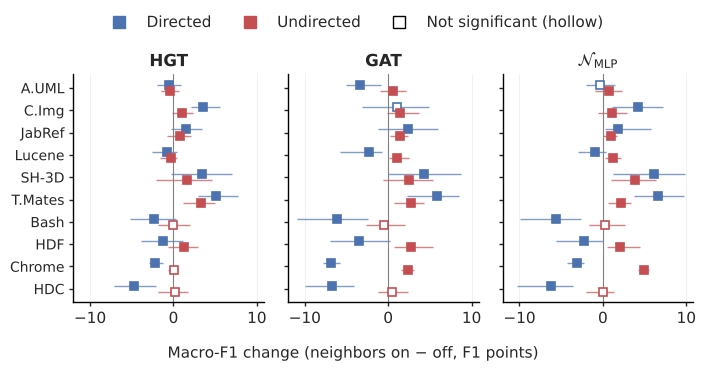

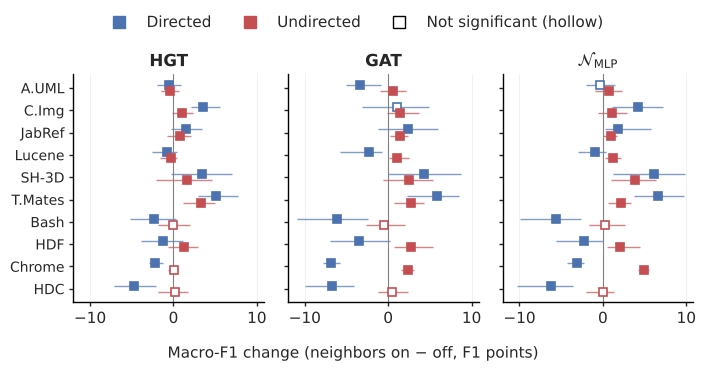

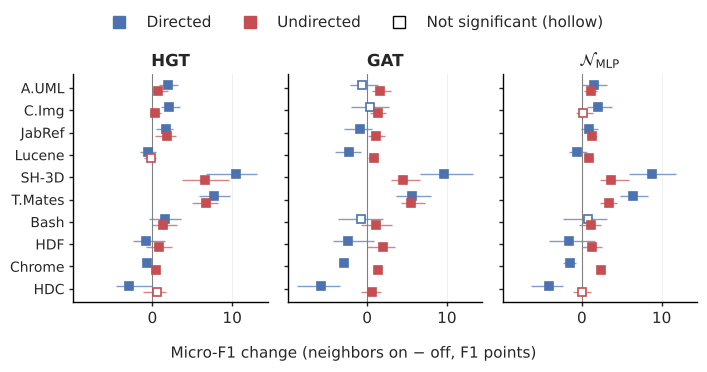

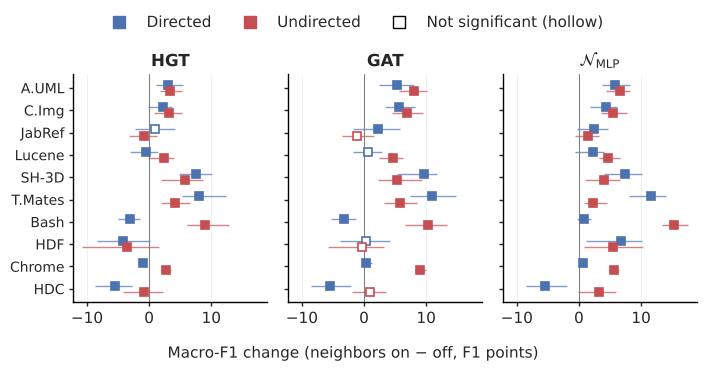

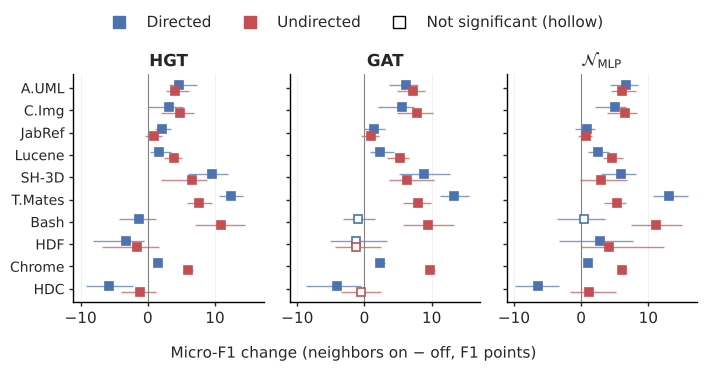

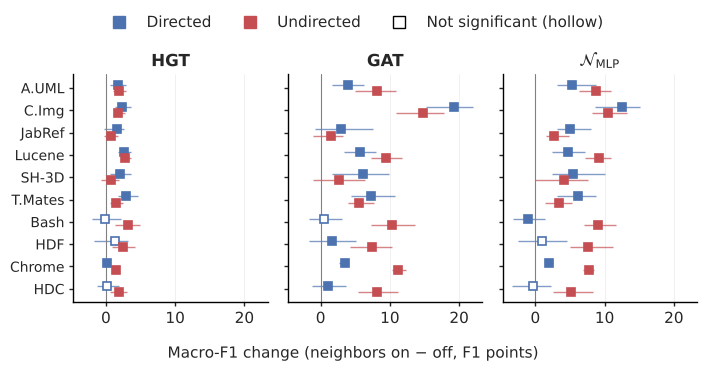

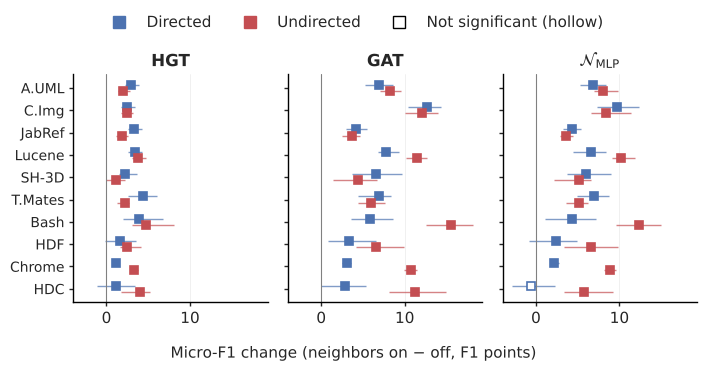

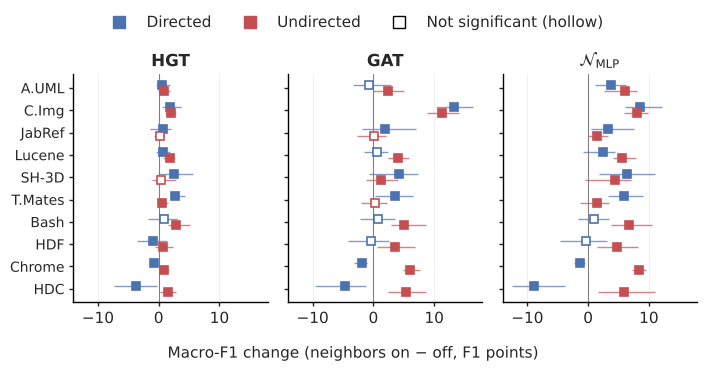

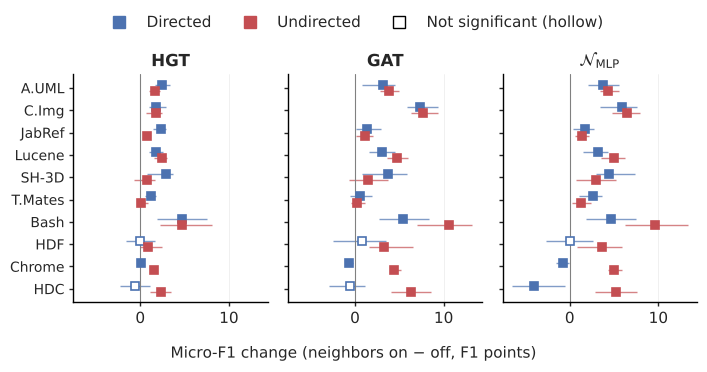

In [8]:
from matplotlib.lines import Line2D

CONTRAST_COLOR = {"directed-off": "#4c72b0", "undirected-off": "#c44e52"}
CONTRAST_LABEL = {"directed-off": "Directed", "undirected-off": "Undirected"}

def fig_onoff(rep="N2V", metric="f1_macro", name=None, size=(7.2, 3.4)):
    d = rq3_stats[(rq3_stats.representation == rep) & (rq3_stats.metric == metric)]
    fig, axes = plt.subplots(1, len(MODELS), figsize=size, sharey=True, sharex=True)
    y0 = np.arange(len(DATASET_ORDER))
    for ax, model in zip(axes, MODELS):
        for j, c in enumerate(["directed-off", "undirected-off"]):
            g = d[(d.model == model) & (d.contrast == c)].set_index("system").reindex(DATASET_ORDER)
            y = y0 + (j - 0.5) * 0.28
            ax.hlines(y, g.q25_paired_delta, g.q75_paired_delta, color=CONTRAST_COLOR[c], lw=1.0, alpha=0.7, zorder=2)
            for yi, (_, r) in zip(y, g.iterrows()):
                ax.plot(r.median_paired_delta, yi, "s", color=CONTRAST_COLOR[c], mfc=CONTRAST_COLOR[c] if r.significant else "white",
                        mew=1.2, ms=5.5, zorder=3)
        ax.axvline(0, color="grey", lw=0.8)
        ax.set_title(MODEL_PLOT[model], fontweight="bold", fontsize=12)
        ax.tick_params(axis="y", labelsize=10)
    axes[0].set_yticks(y0, DATASET_ORDER); axes[0].invert_yaxis()
    fig.supxlabel(f"{METRIC_NAME[metric]} change (neighbors on $-$ off, F1 points)", fontsize=11, y=0.04)
    h = [Line2D([], [], marker="s", color=CONTRAST_COLOR[c], ls="", mfc=CONTRAST_COLOR[c], label=CONTRAST_LABEL[c]) for c in CONTRAST_COLOR]
    h.append(Line2D([], [], marker="s", color="black", ls="", mfc="white", label="Not significant (hollow)"))
    fig.legend(handles=h, loc="upper center", bbox_to_anchor=(0.5, 1.10), ncol=len(h), fontsize=11, frameon=False, markerscale=1.4, columnspacing=1.5)
    fig.tight_layout()
    fig.savefig(fig_path(name or f"rq3_onoff_{rep}_{metric.replace('f1_', '')}.pdf"), bbox_inches="tight")
    plt.show()

fig_onoff("N2V", "f1_macro", name="rq3_n2v.pdf")           # figure used in the paper
for rep in REPS:
    for metric in METRICS:
        if (rep, metric) != ("N2V", "f1_macro"):
            fig_onoff(rep, metric)
        else:
            fig_onoff(rep, metric, name="rq3_onoff_N2V_macro.pdf")

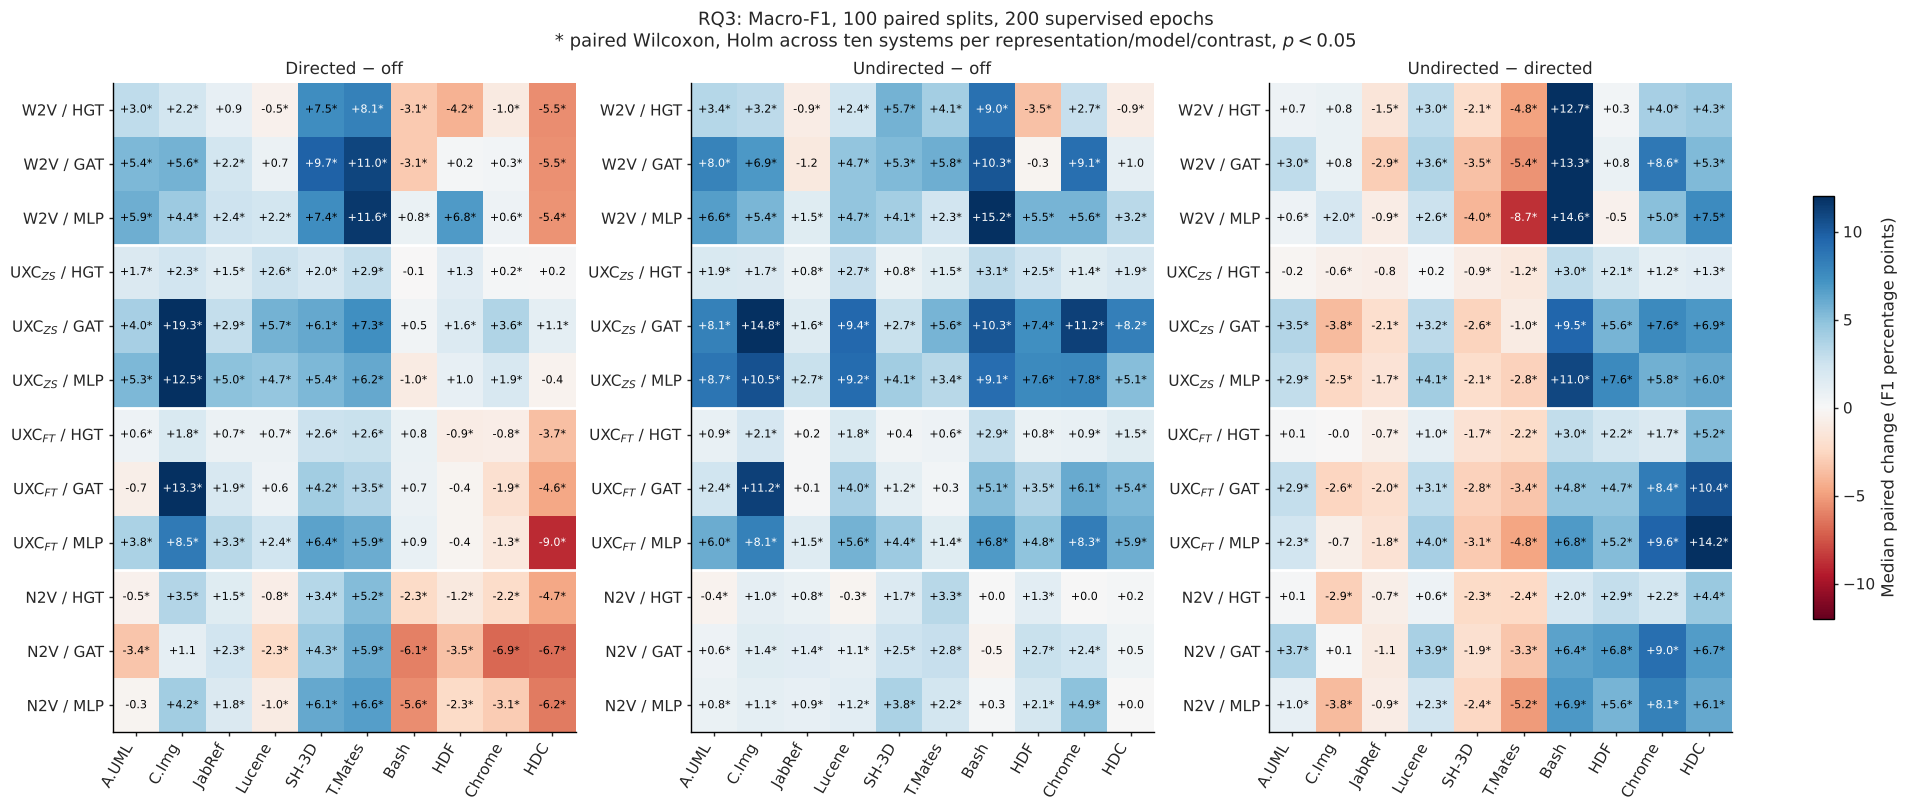

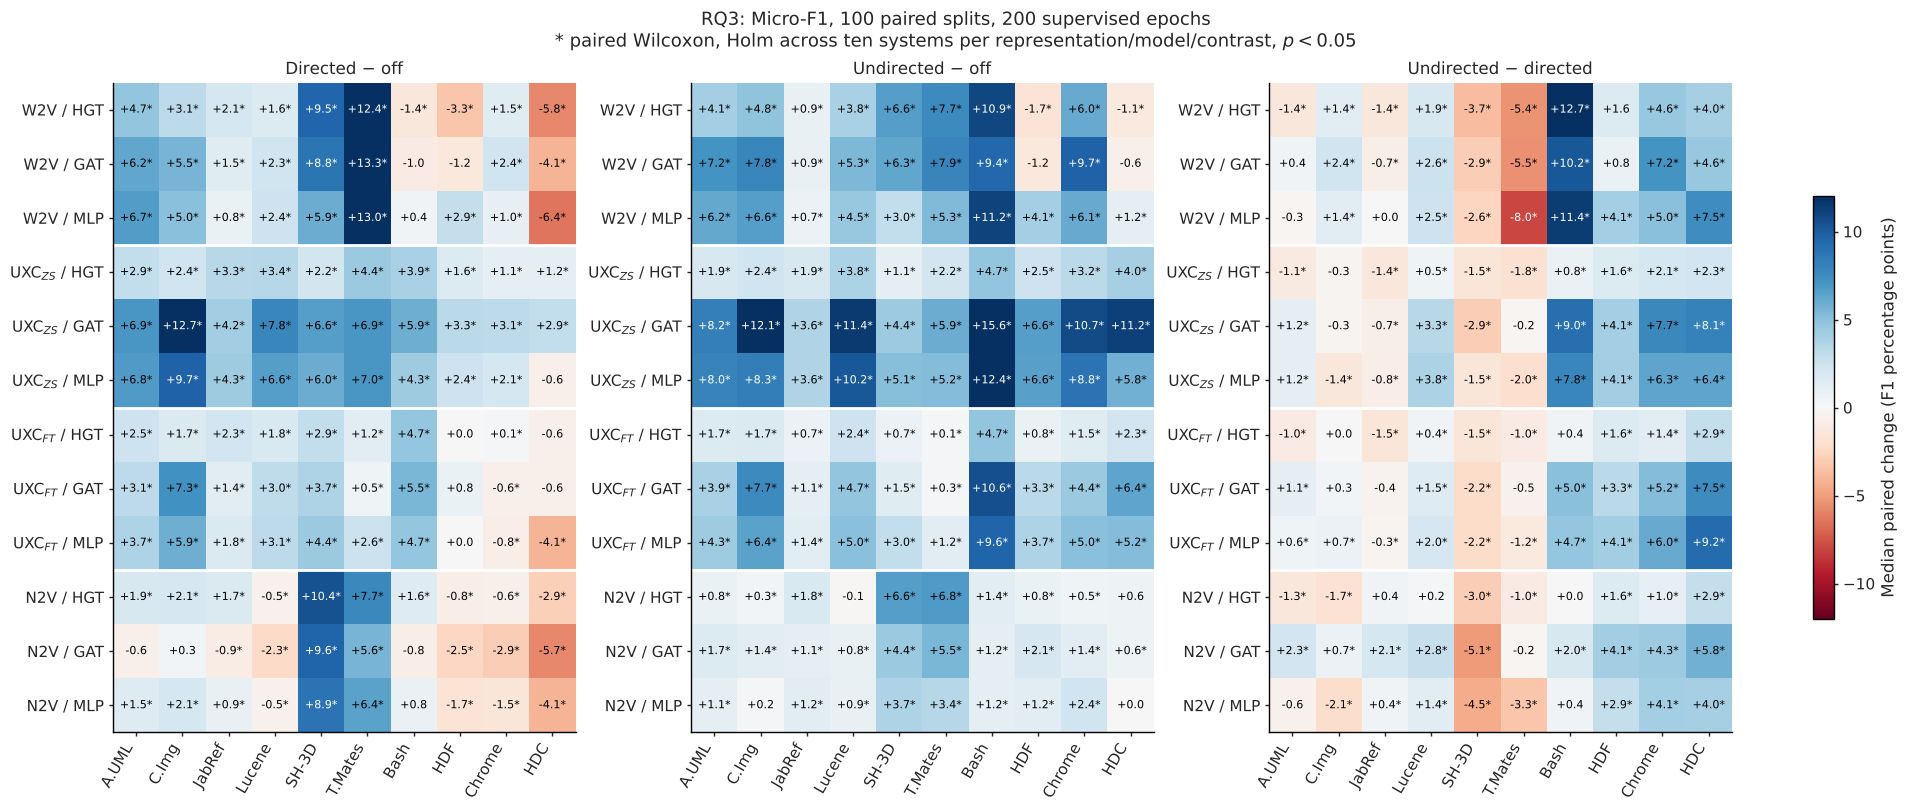

In [9]:
def heatmap(metric):
    reps = ["W2V", "UXC_ZS", "UXC_FT", "N2V"]
    fig, axes = plt.subplots(1, 3, figsize=(19, 8), layout="constrained")
    for ax, (a, b), title in zip(axes, CONTRASTS, [r"Directed $-$ off", r"Undirected $-$ off", r"Undirected $-$ directed"]):
        d = rq3_stats[(rq3_stats.metric == metric) & (rq3_stats.contrast == f"{a}-{b}")].set_index(["representation", "model", "system"])
        mat = np.array([[d.loc[(rep, model, s), "median_paired_delta"] for s in DATASET_ORDER] for rep in reps for model in MODELS])
        im = ax.imshow(mat, cmap="RdBu", vmin=-12, vmax=12, aspect="auto")
        ax.set_xticks(range(10), DATASET_ORDER, rotation=60, ha="right")
        ax.set_yticks(range(12), [f"{REP_PLOT[rep]} / {model.replace('NeighborMLP', 'MLP')}" for rep in reps for model in MODELS])
        ax.set_title(title)
        for i, (rep, model) in enumerate((r, m) for r in reps for m in MODELS):
            for j, s in enumerate(DATASET_ORDER):
                star = "*" if d.loc[(rep, model, s), "significant"] else ""
                ax.text(j, i, f"{mat[i, j]:+.1f}{star}", ha="center", va="center", fontsize=8, color="white" if abs(mat[i, j]) > 8 else "black")
        for y in (2.5, 5.5, 8.5):
            ax.axhline(y, color="white", lw=2)
        ax.grid(False)
    fig.colorbar(im, ax=axes, label="Median paired change (F1 percentage points)", shrink=.65)
    fig.suptitle(f"RQ3: {METRIC_NAME[metric]}, 100 paired splits, 200 supervised epochs\n* paired Wilcoxon, Holm across ten systems per representation/model/contrast, $p<0.05$", fontsize=13)
    fig.savefig(fig_path(f"rq3_effects_heatmap_{metric.replace('f1_', '')}.pdf"))
    plt.show()

for metric in METRICS:
    heatmap(metric)

---
## 8. Which predictor is best on each graph?

Absolute scores with neighbors off / directed / undirected. Cells are the **median over systems of the per-system median** score; in parentheses the number of
systems (of ten) where that predictor has the highest per-system median. These wins share the same ten systems; they are not independent datasets and not significance claims
(paired GAT-HGT / MLP-HGT / GAT-MLP tests are in `rq3_encoder_paired_statistics.csv`). Absolute performance and benefit from neighbors are different questions:
with neighbors off GAT can still beat the feature-only neighbor-MLP, so a stronger architecture need not owe its advantage to message passing (parameter counts differ).

In [10]:
med = rq3.groupby(["system", "representation", "model", "condition"])[METRICS].median().reset_index()
med["system"] = med["system"].replace(SYS_RENAME)

def encoder_table(metric, cond):
    t = med[med.condition == cond].pivot(index=["system", "representation"], columns="model", values=metric)[MODELS]
    # exact ties (e.g. SH-3D micro with N2V and neighbors off) go to the first model in alphabetical order, as in the package
    ties = int((t.eq(t.max(axis=1), axis=0).sum(axis=1) > 1).sum())
    if ties:
        print(f"  note: {ties} system x representation cell(s) with an exact tie in the maximum ({metric}, {cond})")
    wins = (t[sorted(MODELS)].idxmax(axis=1).groupby(level="representation").value_counts().unstack(fill_value=0)
            .reindex(columns=MODELS, fill_value=0))
    center = t.groupby(level="representation").median()[MODELS]
    return center.reindex(REPS), wins.reindex(REPS)

enc = {}
for metric in METRICS:
    for cond in ["off", "directed", "undirected"]:
        enc[(metric, cond)] = encoder_table(metric, cond)
        c, w = enc[(metric, cond)]
        print(f"=== {METRIC_NAME[metric]}, neighbors {cond}: median over systems | wins ===")
        display(c.round(1).astype(str) + " (" + w.astype(str) + ")")

# the supervisor's win table (ties broken by idxmax order, exactly as here)
ref = PKG.csv(f"{AUDIT_DIR}/encoder_wins.csv")
for (metric, cond), (c, w) in enc.items():
    for rep in REPS:
        for model in MODELS:
            got = int(w.loc[rep, model])
            exp = ref[(ref.metric == metric) & (ref.condition == cond) & (ref.representation == rep) & (ref.model == model)].wins
            assert got == (int(exp.iloc[0]) if len(exp) else 0), (metric, cond, rep, model)
print("OK: win counts reproduce encoder_wins.csv")

=== Macro-F1, neighbors off: median over systems | wins ===


model,HGT,GAT,NeighborMLP
representation,,,
N2V,48.1 (2),48.1 (5),42.6 (3)
W2V,37.4 (4),37.4 (6),26.6 (0)
UXC_ZS,42.0 (7),41.9 (3),36.6 (0)
UXC_FT,48.9 (5),49.0 (4),46.1 (1)


=== Macro-F1, neighbors directed: median over systems | wins ===


model,HGT,GAT,NeighborMLP
representation,,,
N2V,48.1 (6),46.4 (0),47.8 (4)
W2V,37.6 (0),41.1 (10),28.4 (0)
UXC_ZS,43.0 (1),46.1 (9),43.0 (0)
UXC_FT,49.2 (4),49.4 (5),48.5 (1)


=== Macro-F1, neighbors undirected: median over systems | wins ===


...

=== Micro-F1, neighbors directed: median over systems | wins ===


model,HGT,GAT,NeighborMLP
representation,,,
N2V,74.3 (9),71.9 (0),71.1 (1)
W2V,56.3 (1),58.2 (8),48.4 (1)
UXC_ZS,62.7 (0),69.5 (10),64.4 (0)
UXC_FT,73.0 (4),73.9 (6),69.9 (0)


=== Micro-F1, neighbors undirected: median over systems | wins ===


model,HGT,GAT,NeighborMLP
representation,,,
N2V,74.0 (5),73.7 (4),72.2 (1)
W2V,59.6 (1),63.2 (9),54.2 (0)
UXC_ZS,62.3 (0),69.8 (10),64.8 (0)
UXC_FT,72.4 (0),76.5 (10),72.6 (0)


OK: win counts reproduce encoder_wins.csv

In [11]:
def tex_encoders():
    L = [r"\begin{table*}[t]", r"\centering",
         r"\caption{Median F1 over ten systems for each predictor on the directed and the undirected file graph, by input vector. "
         r"In parentheses: number of systems on which the predictor has the highest median score. Highlighted: highest median in each row and graph condition. "
         r"HGT, GAT and \mlp{} have different parameter counts.\label{tab:rq3_encoders}}",
         r"\begin{adjustbox}{max width=\textwidth}", r"\renewcommand{\arraystretch}{1.1}", r"\begin{tabular}{llrrrrrr}", r"\toprule",
         r"& & \multicolumn{3}{c}{Directed} & \multicolumn{3}{c}{Undirected} \\", r"\cmidrule(lr){3-5}\cmidrule(lr){6-8}",
         r"Metric & Vector & HGT & GAT & \mlp{} & HGT & GAT & \mlp{} \\", r"\midrule"]
    for mi, metric in enumerate(["f1_macro", "f1_micro"]):
        for ri, rep in enumerate(REPS):
            cells_ = []
            for cond in ("directed", "undirected"):
                c, w = enc[(metric, cond)]
                best = c.loc[rep].idxmax()
                for model in MODELS:
                    t = f"{c.loc[rep, model]:.1f} ({int(w.loc[rep, model])})"
                    cells_.append(rf"\best{{{t}}}" if model == best else t)
            first = rf"\multirow{{4}}{{*}}{{{METRIC_NAME[metric].replace('-F1', ' F1')}}}" if ri == 0 else ""
            L.append(f"{first} & {REP_LABEL[rep]} & " + " & ".join(cells_) + r" \\")
        if mi == 0:
            L.append(r"\midrule")
    L += [r"\bottomrule", r"\end{tabular}", r"\end{adjustbox}", r"\end{table*}", ""]
    return "\n".join(L)

save_tex(tex_encoders(), "rq3_encoders.tex")

# paired encoder contrasts: how many systems are significantly in favor of each side
x = enc_summary[enc_summary.metric == "f1_macro"].pivot_table(
    index=["condition", "representation"], columns="contrast",
    values=["median_system_paired_delta", "significant_positive", "significant_negative"])
display(x.round(2))

wrote generated/rq3_encoders.tex


median_system_paired_delta                  \
contrast                                     GAT-HGT GAT-NeighborMLP   
condition  representation                                              
directed   N2V                                 -2.12           -0.37   
           UXC_FT                               0.12            1.94   
           UXC_ZS                               2.60            3.13   
           W2V                                  1.23            6.29   
off        N2V                                 -0.10            0.23   
           UXC_FT                              -0.02            4.78   
           UXC_ZS                              -0.07            3.72   
           W2V                                  0.07            6.44   
undirected N2V                                  0.43            0.58   
           UXC_FT                               2.32            2.28   
           UXC_ZS                               6.05            3.61   
           W2V                                  2.07            6.17   

                                          significant_negative  \
contrast                  NeighborMLP-HGT              GAT-HGT   
condition  representation                                        
directed   N2V                      -0.88                  7.0   
           UXC_FT                   -2.57                  2.0   
           UXC_ZS                   -1.21                  0.0   
           W2V                      -4.98                  0.0   
off        N2V                      -0.32                  0.0   
           UXC_FT                   -5.37                  0.0   
           UXC_ZS                   -3.80                  1.0   
           W2V                      -6.03                  0.0   
undirected N2V                      -0.23                  0.0   
           UXC_FT                   -1.31                  0.0   
           UXC_ZS                    1.93                  0.0   
           W2V                      -4.43                  0.0   

                                                           \
contrast                  GAT-NeighborMLP NeighborMLP-HGT   
condition  representation                                   
directed   N2V                        3.0             4.0   
           UXC_FT                     0.0             6.0   
           UXC_ZS                     0.0             5.0   
           W2V                        0.0             9.0   
off        N2V                        0.0             3.0   
           UXC_FT                     0.0             9.0   
           UXC_ZS                     0.0            10.0   
           W2V                        0.0            10.0   
undirected N2V                        0.0             2.0   
           UXC_FT                     0.0             4.0   
           UXC_ZS                     0.0             2.0   
           W2V                        0.0             9.0   

                          significant_positive                                  
contrast                               GAT-HGT GAT-NeighborMLP NeighborMLP-HGT  
condition  representation                                                       
directed   N2V                             0.0             2.0             3.0  
           UXC_FT                          2.0             7.0             1.0  
           UXC_ZS                          8.0            10.0             1.0  
           W2V                             9.0            10.0             0.0  
off        N2V                             0.0             3.0             0.0  
           UXC_FT                          0.0             9.0             0.0  
           UXC_ZS                          0.0            10.0             0.0  
           W2V                             0.0            10.0             0.0  
undirected N2V                             4.0             2.0             2.0  
           UXC_FT                          7.0             6.0    

---
## 9. Numbers for the text and checks against the package

In [12]:
def delta(rep, model, contrast, metric="f1_macro"):
    return summ_row(rep, model, contrast, metric)

print("N2V, macro-F1, median system paired change (positive systems; sig+/sig-):")
for model in MODELS:
    for a, b in CONTRASTS:
        r = delta("N2V", model, f"{a}-{b}")
        print(f"  {MODEL_TEX[model]:>8} {a}-{b:<11} {r.median_system_paired_delta:+.2f}  ({r.paired_positive_systems}; {r.significant_positive}/{r.significant_negative})")

print("\nSystems where undirected is WORSE than directed (negative paired median), per representation/model, macro-F1:")
neg = rq3_stats[(rq3_stats.contrast == "undirected-directed") & (rq3_stats.metric == "f1_macro") & (rq3_stats.median_paired_delta < 0)]
display(neg.groupby(["representation", "model"]).system.apply(list).unstack())

print("\nSystems with a Holm-significant LOSS from neighbors, N2V macro-F1:")
loss = rq3_stats[(rq3_stats.representation == "N2V") & (rq3_stats.metric == "f1_macro") & rq3_stats.significant & (rq3_stats.median_paired_delta < 0)
                 & rq3_stats.contrast.isin(["directed-off", "undirected-off"])]
display(loss.groupby(["model", "contrast"]).system.apply(list))

print("\nGAT wins on the undirected graph (system x representation cells, of 40):")
for metric in METRICS:
    tot = sum(int(enc[(metric, "undirected")][1].loc[rep, "GAT"]) for rep in REPS)
    per = {rep: int(enc[(metric, "undirected")][1].loc[rep, "GAT"]) for rep in REPS}
    print(f"  {METRIC_NAME[metric]}: {tot}/40  {per}")
print("Directed graph, N2V: HGT wins", dict(enc[("f1_macro", "directed")][1].loc["N2V"]), "(macro)", dict(enc[("f1_micro", "directed")][1].loc["N2V"]), "(micro)")

print("\nNeighbors off, GAT minus neighbor-MLP (median system difference, F1 points):")
display(enc_summary[(enc_summary.condition == "off") & (enc_summary.contrast == "GAT-NeighborMLP")]
        .pivot_table(index="representation", columns="metric", values="median_system_difference").round(2))

N2V, macro-F1, median system paired change (positive systems; sig+/sig-):
       HGT directed-off         -0.64  (4; 4/6)
       HGT undirected-off         +0.49  (8; 5/2)
       HGT undirected-directed    +0.34  (6; 5/4)
       GAT directed-off         -2.84  (4; 3/6)
       GAT undirected-off         +1.42  (9; 8/0)
       GAT undirected-directed    +3.81  (7; 6/2)
    \mlp{} directed-off         -0.65  (4; 4/5)
    \mlp{} undirected-off         +1.19  (10; 8/0)
    \mlp{} undirected-directed    +1.62  (6; 6/4)

Systems where undirected is WORSE than directed (negative paired median), per representation/model, macro-F1:


model,GAT,HGT,NeighborMLP
representation,,,
N2V,"[JabRef, SH-3D, T.Mates]","[C.Img, JabRef, SH-3D, T.Mates]","[C.Img, JabRef, SH-3D, T.Mates]"
UXC_FT,"[C.Img, JabRef, SH-3D, T.Mates]","[C.Img, JabRef, SH-3D, T.Mates]","[C.Img, JabRef, SH-3D, T.Mates]"
UXC_ZS,"[C.Img, JabRef, SH-3D, T.Mates]","[A.UML, C.Img, JabRef, SH-3D, T.Mates]","[C.Img, JabRef, SH-3D, T.Mates]"
W2V,"[JabRef, SH-3D, T.Mates]","[JabRef, SH-3D, T.Mates]","[JabRef, SH-3D, T.Mates, HDF]"



Systems with a Holm-significant LOSS from neighbors, N2V macro-F1:


model        contrast      
GAT          directed-off      [A.UML, Lucene, Bash, HDF, Chrome, HDC]
HGT          directed-off      [A.UML, Lucene, Bash, HDF, Chrome, HDC]
             undirected-off                            [A.UML, Lucene]
NeighborMLP  directed-off             [Lucene, Bash, HDF, Chrome, HDC]
Name: system, dtype: object


GAT wins on the undirected graph (system x representation cells, of 40):
  Macro-F1: 33/40  {'N2V': 6, 'W2V': 10, 'UXC_ZS': 10, 'UXC_FT': 7}
  Micro-F1: 33/40  {'N2V': 4, 'W2V': 9, 'UXC_ZS': 10, 'UXC_FT': 10}
Directed graph, N2V: HGT wins {'HGT': np.int64(6), 'GAT': np.int64(0), 'NeighborMLP': np.int64(4)} (macro) {'HGT': np.int64(9), 'GAT': np.int64(0), 'NeighborMLP': np.int64(1)} (micro)

Neighbors off, GAT minus neighbor-MLP (median system difference, F1 points):


metric,f1_macro,f1_micro
representation,,
N2V,0.21,-0.02
UXC_FT,5.20,2.69
UXC_ZS,3.91,1.88
W2V,6.58,5.07


In [13]:
# ── hard checks against the supervisor's REPORT.md ─────────────────────────────────────────
rep_vals = {  # (representation, model, contrast): (median_system_paired_delta, paired_positive_systems, sig+, sig-)
    ("N2V", "GAT", "directed-off"): (-2.84, 4, 3, 6), ("N2V", "HGT", "directed-off"): (-0.64, 4, 4, 6),
    ("N2V", "NeighborMLP", "directed-off"): (-0.65, 4, 4, 5), ("UXC_ZS", "GAT", "directed-off"): (3.79, 10, 9, 0),
    ("W2V", "HGT", "directed-off"): (0.23, 5, 4, 5), ("N2V", "GAT", "undirected-off"): (1.42, 9, 8, 0),
    ("N2V", "HGT", "undirected-off"): (0.49, 8, 5, 2), ("N2V", "NeighborMLP", "undirected-off"): (1.19, 10, 8, 0),
    ("UXC_ZS", "GAT", "undirected-off"): (8.17, 10, 10, 0), ("W2V", "HGT", "undirected-off"): (2.94, 7, 7, 3),
    ("UXC_FT", "NeighborMLP", "undirected-off"): (5.77, 10, 10, 0),
}
for (rep, model, c), (v, pos, sp, sn) in rep_vals.items():
    r = delta(rep, model, c)
    got = (round(r.median_system_paired_delta, 2), r.paired_positive_systems, r.significant_positive, r.significant_negative)
    assert got == (v, pos, sp, sn), ((rep, model, c), got, (v, pos, sp, sn))
# GAT wins on the undirected graph: 33/40 on both metrics (W2V 10, ZS 10, FT 7/10, N2V 6/4)
assert sum(int(enc[("f1_macro", "undirected")][1].loc[r, "GAT"]) for r in REPS) == 33
assert sum(int(enc[("f1_micro", "undirected")][1].loc[r, "GAT"]) for r in REPS) == 33
g = enc_summary[(enc_summary.condition == "off") & (enc_summary.contrast == "GAT-NeighborMLP") & (enc_summary.metric == "f1_macro")].set_index("representation")
assert round(g.loc["W2V", "median_system_difference"], 2) == 6.58 and round(g.loc["UXC_FT", "median_system_difference"], 2) == 5.20
print("OK: all spot checks match REPORT.md")
print("TeX written:", sorted(p.name for p in TEX_DIR.glob("rq3*.tex")))
print("Figures    :", sorted(p.name for p in FIG_DIR.glob("rq3*")))

OK: all spot checks match REPORT.md
TeX written: ['rq3_encoders.tex', 'rq3_n2v.tex', 'rq3_systems_UXC_FT.tex', 'rq3_systems_UXC_ZS.tex', 'rq3_systems_W2V.tex', 'rq3_systems_body.tex']
Figures    : ['rq3_compare_pooled_self.pdf', 'rq3_effects_heatmap_macro.pdf', 'rq3_effects_heatmap_micro.pdf', 'rq3_fig_compare_self.pdf', 'rq3_fig_compare_sup.pdf', 'rq3_n2v.pdf', 'rq3_onoff_N2V_macro.pdf', 'rq3_onoff_N2V_micro.pdf', 'rq3_onoff_UXC_FT_macro.pdf', 'rq3_onoff_UXC_FT_micro.pdf', 'rq3_onoff_UXC_ZS_macro.pdf', 'rq3_onoff_UXC_ZS_micro.pdf', 'rq3_onoff_W2V_macro.pdf', 'rq3_onoff_W2V_micro.pdf']
